In [2]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset

In [2]:
torch.manual_seed(42)

In [12]:
df=pd.read_csv("/content/fashion-mnist_test.csv")

 As in the previous code file we have seen a bit overfitting so to tackle this overfitting there are many technique to address and handle overfitting:  
 1- Adding a more data.  
 2- Reducing the complexity of NN acrchitecture.  
 3- Regularization.  
 4- Dropouts.  
 5- Data Agumentation.  
 6- Batch Normalization.  
 7- Early Stopping

In [13]:
df

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,9,8,...,103.0,87.0,56.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,0,0,0,0,0,0,0,0,0,...,34.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,0,0,0,0,0,0,14,53,99,...,0.0,0.0,0.0,0.0,63.0,53.0,31.0,0.0,0.0,0.0
3,2,0,0,0,0,0,0,0,0,0,...,137.0,126.0,140.0,0.0,133.0,224.0,222.0,56.0,0.0,0.0
4,3,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1881,8,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1882,6,0,0,0,0,0,0,0,0,20,...,35.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1883,9,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1884,9,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f" using:{device}")

 using:cuda


In [6]:
import matplotlib.pyplot as plt


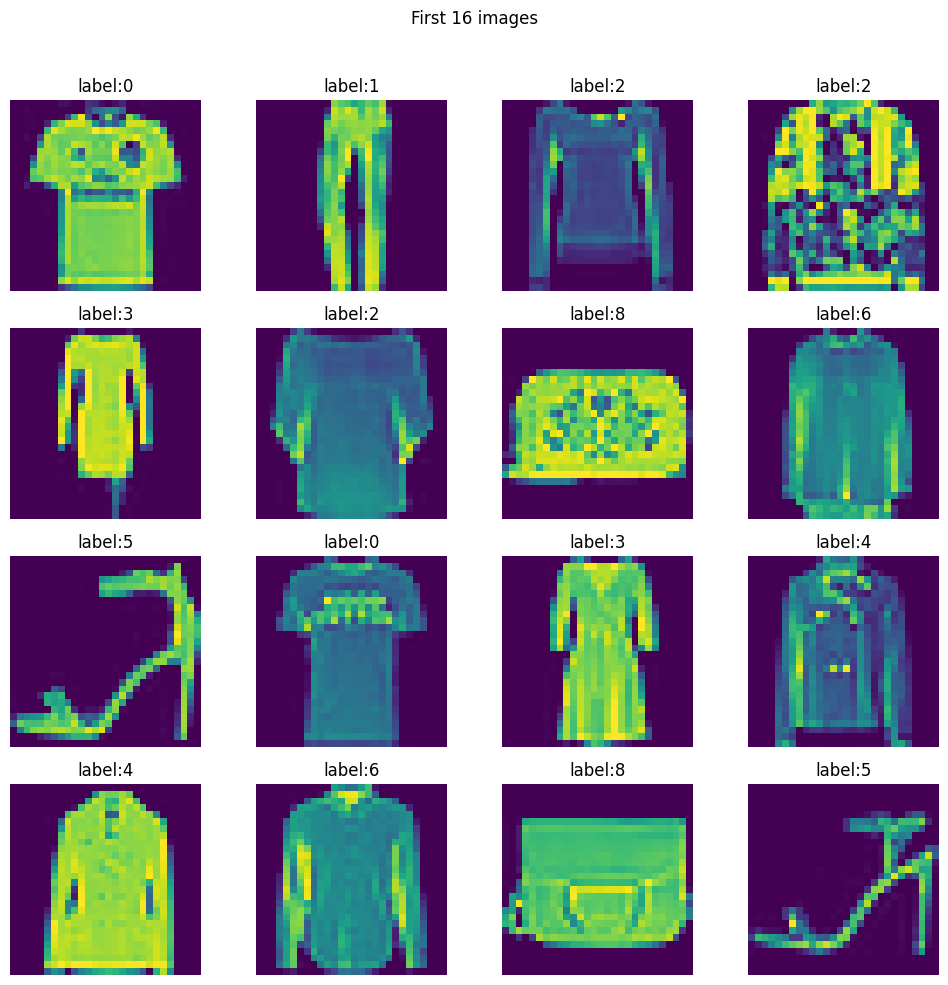

In [14]:
fig,axes=plt.subplots(4,4,figsize=(10,10))
fig.suptitle("First 16 images")

for i,ax in enumerate (axes.flat):
    img=df.iloc[i,1:].values.reshape(28,28)
    ax.imshow(img)
    ax.axis('off')
    ax.set_title(f"label:{df.iloc[i,0]}")
plt.tight_layout(rect=[0,0,1,0.96])
plt.show()

In [15]:
x=df.iloc[:,1:].values
y=df.iloc[:,0].values

In [16]:
x_train,x_test,y_train,y_test=train_test_split(
    x,y,shuffle=True,stratify=y,test_size=0.25
)

In [17]:
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(1414, 784)
(1414,)
(472, 784)
(472,)


In [18]:
x_train=(x_train/255.0)
x_test=(x_test/255.0)

In [19]:
# custom class
class custom(Dataset):
    def __init__(self,feat,label):
        self.feat= torch.tensor(feat, dtype=torch.float32)
        self.label= torch.tensor(label, dtype=torch.long)
    def __len__(self):
        return len(self.feat)
    def __getitem__(self,index):
        return self.feat[index],self.label[index]

In [20]:
train_data=custom(x_train,y_train)

In [22]:
test_data=custom(x_test,y_test)

In [23]:
#create train and test loader
train_loader=DataLoader(
    train_data, batch_size=32, pin_memory=True)
test_loader= DataLoader(
    test_data, batch_size=32, pin_memory=True)

# USing Dropouts

In [ ]:
# # Define neural network class
# class my_nn(nn.Module):

#     def __init__(self, num_feat):
#         super().__init__()

#         self.model = nn.Sequential(
#             nn.Linear(num_feat, 128),
#             nn.ReLU(),
#             nn.Dropout(p=0.27),
#             nn.Linear(128, 64),
#             nn.ReLU(),
#             nn.Dropout(p=0.28),   #. <----------here we used the dropout
#             nn.Linear(64, 10),

#         )

#     def forward(self, x):
#         return self.model(x)



# now using the batch normalization

In [24]:
# from torch.nn.modules.batchnorm import BatchNorm1d
# # Define neural network class
# class my_nn(nn.Module):

#     def __init__(self, num_feat):
#         super().__init__()

#         self.model = nn.Sequential(
#             nn.Linear(num_feat, 128),
#             nn.BatchNorm1d(128);
#             nn.ReLU(),

#             nn.Linear(128, 64),
#             nn.BatchNorm1d(64).  # <---------Here i used the batch normalization
#             nn.ReLU(),

#             nn.Linear(64, 10),

#         )

#     def forward(self, x):
#         return self.model(x)


# Now using Regularization

In [ ]:
# from torch.optim import optimizer
# crit=nn.CrossEntropyLoss()
# optimizer=optim.SGD(model.parameters(), lr=0.1, weight_decay=1e-4)